# Тестирование ГА - обычного и островного
Коллеги, надо постараться сделать, что сможем, мутация инверсией + отбор турниром это жесть

Что нужно протестировать:
- Гиперпараметры: меняем их и строим график зависимости точности решения от размера матрицы. Точность решения определяется расстоянием до оптимального решения, которое возвращает функция ГА
- Улучшения островного ГА по сравнению с обычным. Сначала подбираем гиперпараметры, потом это


In [30]:
import lab1_test_migrations
import matplotlib.pyplot as plt
from lab1_test import run_ga
from itertools import permutations
import random

def generate_matrix(size: int, ideal:bool=False):
    """Генерирует матрицу чисел от 1 до 100 размера size*size
    **Параметры**:\n
    ideal - если True, то генерирует матрицу с ценами 1 по главной диагонали и 100 в остальных позициях"""
    matrix = []
    if ideal:
        matrix = [[100] * size for _ in range(size)] 
        for i in range(size):
            matrix[i][i] = 1
    else:
        matrix = [[random.randint(1, 100) for _ in range(size)] for _ in range(size)]
    return matrix

generate_matrix(4, False)


[[54, 26, 47, 99], [13, 93, 36, 92], [98, 22, 64, 49], [77, 15, 25, 72]]

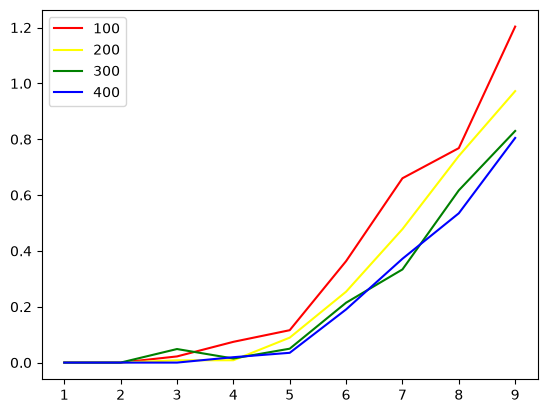

In [31]:
POPULATION_SIZE = 50  # Размер каждой популяции
MUTATION_PROBABILITY = 0.7
TOURNAMENT_SIZE = 2
MAX_ITERATIONS = 1000
PLATEAU_LIMIT = 3
PLATEAU_DIFF = 2e-4

data_x = list(range(1, 10))
data_y = []

def test_ga(sizes, iterations_number, algorythm, params, ideal = False):
    """Функция, тестирующая генетический алгоритм\n
    **Параметры**:\n
    sizes - массив размеров, для которых мы хотим протестировать ГА\n
    iterations_number - количество тестовых массивов, по которым мы усредняем результат ГА\n
    ?ideal - тестируем ли мы на идеальных матрицах"""

    y = [0] * len(sizes)
    for i in range(len(sizes)):
        for _ in range(iterations_number):
            matrix = generate_matrix(sizes[i], ideal)
            _, _, dist = algorythm(*params.values(), matrix=matrix)
            y[i] += dist
    y = [i / iterations_number for i in y]
    return y

usual_params = {
    "POPULATION_SIZE": 300,
    "MUTATION_PROBABILITY": 1,
    "TOURNAMENT_SIZE": 2,
    "MAX_ITERATIONS": 1000,
    "PLATEAU_LIMIT": 3,
    "PLATEAU_DIFF": 2e-4
}

migration_params = {
    "POPULATION_SIZE": 300,
    "MUTATION_PROBABILITY": 0.9,
    "TOURNAMENT_SIZE": 2,
    "MAX_ITERATIONS": 1000,
    "PLATEAU_LIMIT": 3,
    "PLATEAU_DIFF": 2e-4,
    "MIGRATION_INTERVAL": 10,
    "MIGRATION_PERCENT": 10,
    "NUM_ISLANDS": 3
}

colors = ['red', 'yellow', 'green', 'blue', 'magenta']

for i in range(1, 5):
    usual_params["POPULATION_SIZE"] = i * 100
    data_y = test_ga(data_x, 100, run_ga, usual_params)
    plt.plot(data_x, data_y, color=colors[i - 1], label=str(i * 100))

plt.legend()
plt.show()




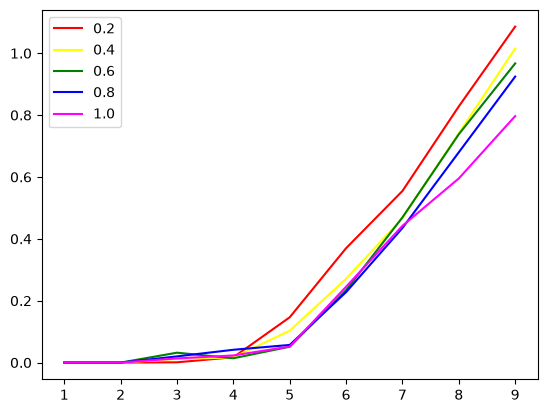

In [32]:
usual_params["POPULATION_SIZE"] = 300

for i in range(1, 6):
    usual_params["MUTATION_PROBABILITY"] = i / 5
    data_y = test_ga(data_x, 100, run_ga, usual_params)
    plt.plot(data_x, data_y, color=colors[i - 1], label=str(i/5))

plt.legend()
plt.show()

Оптимальная вероятность мутации - 0.8

## Тестирование островного ГА в сравнении с обычным

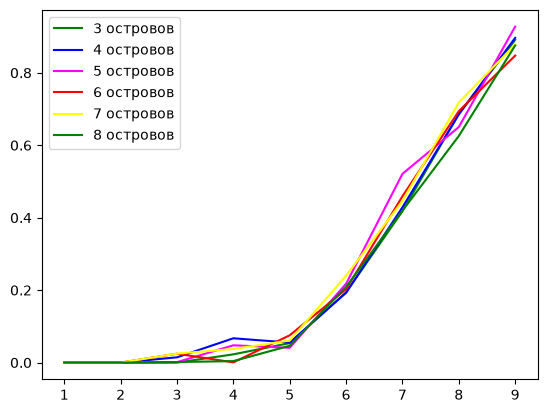

In [33]:
migration_params["MUTATION_PROBABILITY"] = 0.8
usual_params["MUTATION_PROBABILITY"] = 0.8

for i in range(3, 9):
    migration_params["NUM_ISLANDS"] = i
    migration_params["POPULATION_SIZE"] = 300 // i
    data_y = test_ga(data_x, 100, lab1_test_migrations.run_ga_with_migrations, migration_params)
    plt.plot(data_x, data_y, color=colors[(i - 1) % 5], label=f'{i} островов')

plt.legend()
plt.show()

## Математическое обоснование того, почему у нас плохая модель

Мутация инверсией - по сути своей, циклический сдвиг. Т.е если у нас решение - вектор длины n, то из него мы можем получить максимум n возможных решений путем мутации. 

При этом размерность пространства всех возможных решений имеет размерность n!, а пространство наших решений имеет максимальную возможную размерность population_size * n, т.к. из каждого решения мы можем получить n других.

Таким образом, размерность нашего пространства решений к общему относится как $P=\frac{population_size * n}{n!}=\frac{population_size}{(n - 1)!}$

Мы не можем взять размер популяции заметно больше 1000; уже при n = 8 $P_{max} = \frac{1000}{7!} = 0.2$; т.е вероятность того, что оптимальное решение будет присутствовать в пространстве решений, равна максимум 0.2